# Titanic dataset catboost

In [50]:
import pandas as pd
from seaborn import load_dataset

df = load_dataset('titanic')



print(df.head())
print(df.info())
print(df.describe())
print(df.shape)

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64

# Data cleaning

In [51]:
# make a copy of datset in new variable
df = df.copy()

print(df.isnull().sum() / len(df) * 100) # show in percent
# deck           0.772166 = too many missing values / we should drop
print(df.duplicated().sum()) # 107 duplicates


df = df.drop(columns='deck')
df = df.drop_duplicates()

df['age'] = df['age'].fillna(df['age'].mean())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode(0))

print(df.isnull().sum())
print(df.duplicated().sum())

survived        0.000000
pclass          0.000000
sex             0.000000
age            19.865320
sibsp           0.000000
parch           0.000000
fare            0.000000
embarked        0.224467
class           0.000000
who             0.000000
adult_male      0.000000
deck           77.216611
embark_town     0.224467
alive           0.000000
alone           0.000000
dtype: float64
107
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       2
class          0
who            0
adult_male     0
embark_town    2
alive          0
alone          0
dtype: int64
0


In [52]:
for column in df.columns:
    print(f'\n{column}:')
    print(df[column].value_counts().head(10))

# adult man is useless because the number of adult man can be seen in feature called sex


survived:
survived
0    458
1    322
Name: count, dtype: int64

pclass:
pclass
3    404
1    212
2    164
Name: count, dtype: int64

sex:
sex
male      488
female    292
Name: count, dtype: int64

age:
age
29.812751    104
24.000000     29
18.000000     25
22.000000     24
19.000000     23
28.000000     22
21.000000     22
30.000000     22
36.000000     21
25.000000     20
Name: count, dtype: int64

sibsp:
sibsp
0    513
1    201
2     27
4     18
3     14
5      5
8      2
Name: count, dtype: int64

parch:
parch
0    576
1    114
2     75
5      5
3      5
4      4
6      1
Name: count, dtype: int64

fare:
fare
13.0000    31
26.0000    30
8.0500     25
10.5000    23
7.8958     20
7.7500     20
7.9250     16
7.7750     16
26.5500    14
7.8542     12
Name: count, dtype: int64

embarked:
embarked
S    565
C    155
Q     58
Name: count, dtype: int64

class:
class
Third     404
First     212
Second    164
Name: count, dtype: int64

who:
who
man      448
woman    250
child     82
Name: cou

# Complete Eda report

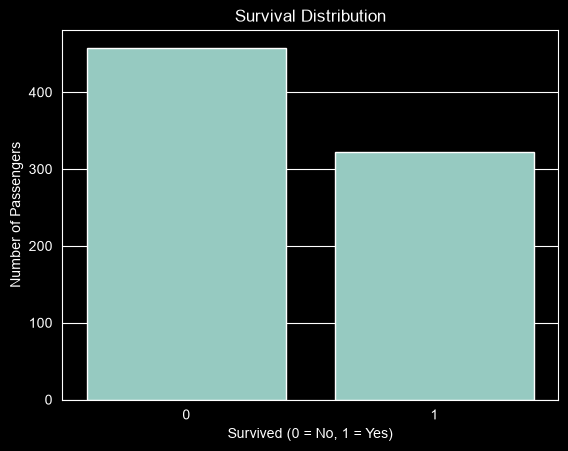

survived
0    58.717949
1    41.282051
Name: proportion, dtype: float64


In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

# survival distribution
sns.countplot(data=df, x='survived')

plt.title('Survival Distribution')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Number of Passengers')
plt.show()

print(df['survived'].value_counts(normalize=True) * 100)

## Categorical feature analysis

sex
female    73.972603
male      21.721311
Name: survived, dtype: float64


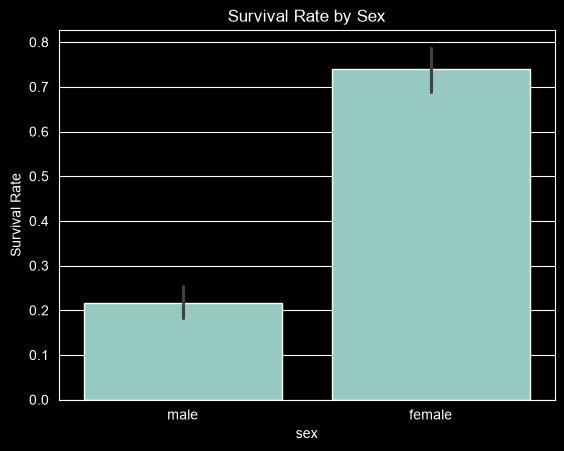

In [54]:
# survival rate by gender
survival_by_sex = df.groupby('sex')['survived'].mean() * 100

print(survival_by_sex)

sns.barplot(data=df, x='sex', y='survived')

plt.title('Survival Rate by Sex')
plt.ylabel('Survival Rate')
plt.show()

pclass
1    63.679245
2    50.609756
3    25.742574
Name: survived, dtype: float64


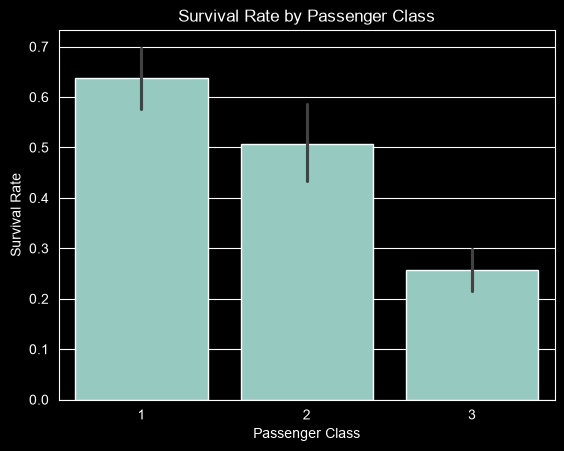

In [55]:
# survival rate by passanger class
survival_by_class = df.groupby('pclass')['survived'].mean() * 100

print(survival_by_class)

sns.barplot(data=df, x='pclass', y='survived')

plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.show()

embarked
C    58.064516
Q    34.482759
S    37.168142
Name: survived, dtype: float64


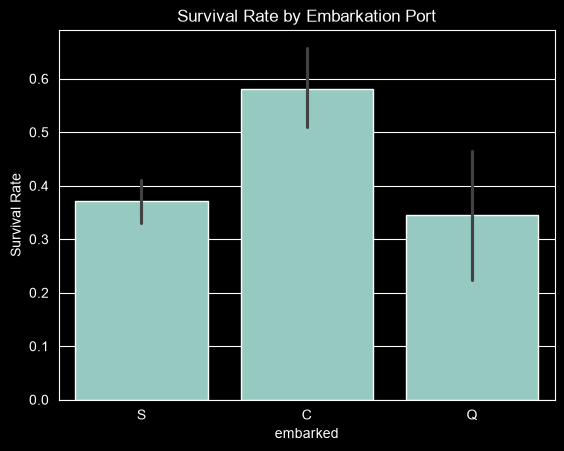

In [56]:
# survival rate by port
survival_by_embarked = df.groupby('embarked')['survived'].mean() * 100

print(survival_by_embarked)

sns.barplot(data=df, x='embarked', y='survived')

plt.title('Survival Rate by Embarkation Port')
plt.ylabel('Survival Rate')
plt.show()

## Numerical feature analysis

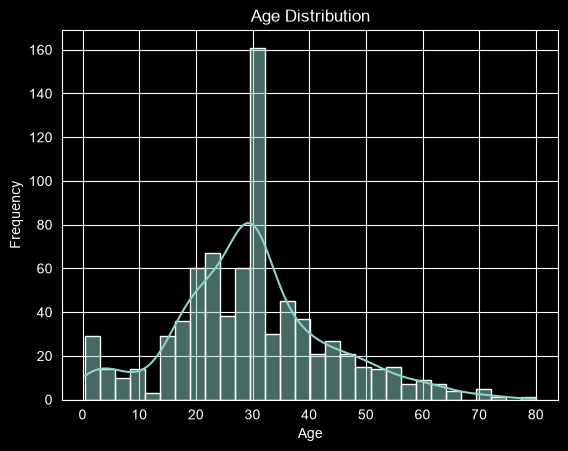

count    780.000000
mean      29.812751
std       13.708828
min        0.420000
25%       21.750000
50%       29.812751
75%       36.000000
max       80.000000
Name: age, dtype: float64


In [57]:
# age distribuition
sns.histplot(data=df, x='age', bins=30, kde=True)

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

print(df['age'].describe())

age_group
Child          57.352941
Teenager       44.776119
Young Adult    39.722864
Adult          39.790576
Senior         23.809524
Name: survived, dtype: float64


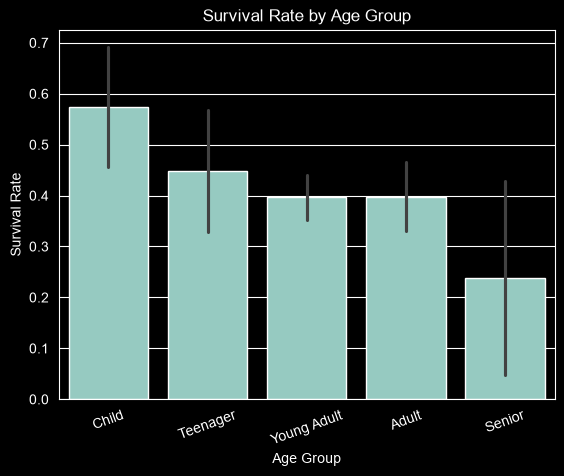

In [58]:
# survival rate by age groups
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 12, 18, 35, 60, 100],
    labels=['Child', 'Teenager', 'Young Adult', 'Adult', 'Senior']
)

survival_by_age = df.groupby('age_group', observed=True)['survived'].mean() * 100

print(survival_by_age)

sns.barplot(data=df, x='age_group', y='survived')

plt.title('Survival Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Survival Rate')
plt.xticks(rotation=20)
plt.show()

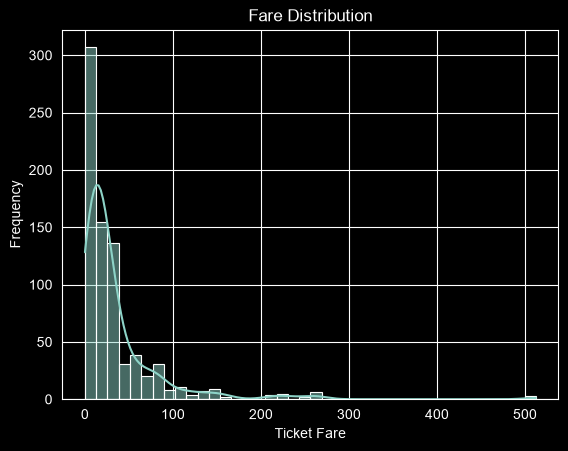

count    780.000000
mean      34.829108
std       52.263440
min        0.000000
25%        8.050000
50%       15.950000
75%       34.375000
max      512.329200
Name: fare, dtype: float64


In [59]:
# Fare distribution
sns.histplot(data=df, x='fare', bins=40, kde=True)

plt.title('Fare Distribution')
plt.xlabel('Ticket Fare')
plt.ylabel('Frequency')
plt.show()

print(df['fare'].describe())

fare_group
(-0.001, 8.05]       23.584906
(8.05, 15.95]        35.393258
(15.95, 34.375]      44.949495
(34.375, 512.329]    62.500000
Name: survived, dtype: float64


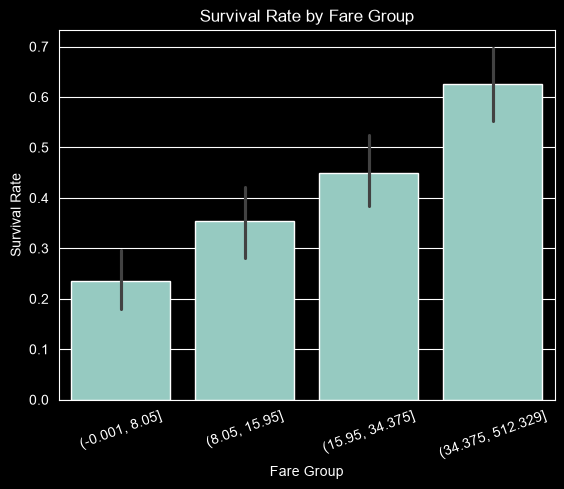

In [60]:
# Survival rate
df['fare_group'] = pd.qcut(
    df['fare'],
    q=4,
    duplicates='drop'
)

survival_by_fare = df.groupby('fare_group', observed=True)['survived'].mean() * 100

print(survival_by_fare)

sns.barplot(data=df, x='fare_group', y='survived')

plt.title('Survival Rate by Fare Group')
plt.xlabel('Fare Group')
plt.ylabel('Survival Rate')
plt.xticks(rotation=20)
plt.show()

family_size
1     442
2     154
3     101
4      28
5      13
6      22
7      12
8       6
11      2
Name: count, dtype: int64


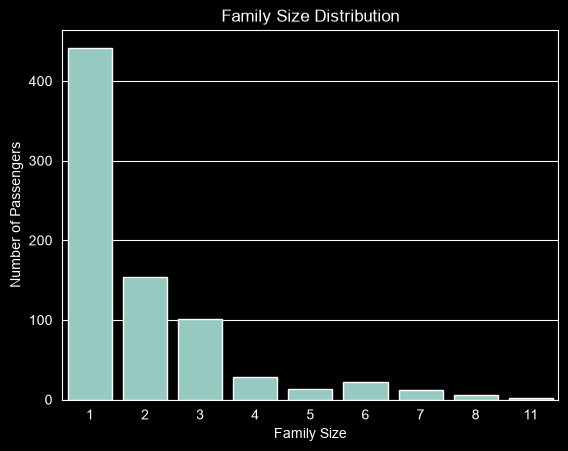

In [61]:
# create family size
df['family_size'] = df['sibsp'] + df['parch'] + 1

print(df['family_size'].value_counts().sort_index())

# family size distribution visually
sns.countplot(data=df, x='family_size')

plt.title('Family Size Distribution')
plt.xlabel('Family Size')
plt.ylabel('Number of Passengers')
plt.show()

family_size
1     33.710407
2     55.194805
3     57.425743
4     71.428571
5     23.076923
6     13.636364
7     33.333333
8      0.000000
11     0.000000
Name: survived, dtype: float64


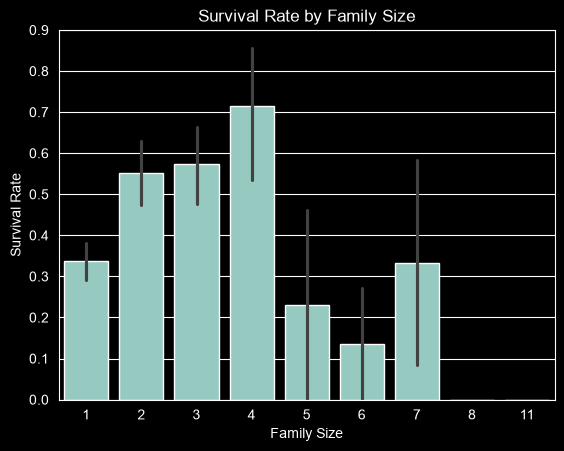

In [62]:
# survival rate by family size
survival_by_family = df.groupby('family_size')['survived'].mean() * 100

print(survival_by_family)

sns.barplot(data=df, x='family_size', y='survived')

plt.title('Survival Rate by Family Size')
plt.xlabel('Family Size')
plt.ylabel('Survival Rate')
plt.show()

# XGboost vs LightGBM vs CatBoost

### feature selection

In [63]:
# alive — target leakage || embark_town — duplicate of embarked || adult_male, who, alone - redundant information

# Create features and target
features = [
    'pclass',
    'sex',
    'embarked',
    'age',
    'fare',
    'sibsp',
    'parch',
    'family_size'
]

X = df[features].copy()
y = df['survived'].copy()

print(X.head())
print(X.shape)

   pclass     sex embarked   age     fare  sibsp  parch  family_size
0       3    male        S  22.0   7.2500      1      0            2
1       1  female        C  38.0  71.2833      1      0            2
2       3  female        S  26.0   7.9250      0      0            1
3       1  female        S  35.0  53.1000      1      0            2
4       3    male        S  35.0   8.0500      0      0            1
(780, 8)


In [64]:
from sklearn.model_selection import train_test_split

#split train/valid/test
X_train_valid, X_test, y_train_valid, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Second: separate validation set (approximately 15% overall)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_valid, y_train_valid,
    test_size=0.2,
    random_state=42,
    stratify=y_train_valid
)

In [65]:
# handle missing values
cat_features = ['pclass', 'sex', 'embarked']

num_features = [
    'age',
    'fare',
    'sibsp',
    'parch',
    'family_size'
]

# Numerical missing values
for col in num_features:
    median_value = X_train[col].median()

    X_train[col] = X_train[col].fillna(median_value)
    X_valid[col] = X_valid[col].fillna(median_value)
    X_test[col] = X_test[col].fillna(median_value)

# Categorical missing values
for col in cat_features:
    X_train[col] = X_train[col].fillna('Unknown').astype(str)
    X_valid[col] = X_valid[col].fillna('Unknown').astype(str)
    X_test[col] = X_test[col].fillna('Unknown').astype(str)

In [66]:
# XGBoost and LightGBM
X_train_tree = X_train
X_valid_tree = X_valid
X_test_tree = X_test

for col in cat_features:
    for data in [X_train_tree, X_valid_tree, X_test_tree]:
        data[col] = data[col].astype('category')

# CatBoost
X_train_cat = X_train
X_valid_cat = X_valid
X_test_cat = X_test

### XGBoost

In [67]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    enable_categorical=True,
    tree_method='hist',
    eval_metric='logloss',
    early_stopping_rounds=50,
    random_state=42
)

xgb_model.fit(
    X_train_tree,
    y_train,
    eval_set=[(X_valid_tree, y_valid)],
    verbose=False
)

print('Best iteration:', xgb_model.best_iteration)
print('Best score:', xgb_model.best_score)

Best iteration: 56
Best score: 0.44374825513362887


### LightGBM

In [68]:
from lightgbm import LGBMClassifier, early_stopping, log_evaluation

lgbm_model = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=15,
    max_depth=-1,
    verbosity=-1,
    random_state=42
)

lgbm_model.fit(
    X_train_tree,
    y_train,
    eval_set=[(X_valid_tree, y_valid)],
    callbacks=[
        early_stopping(50),
        log_evaluation(0)
    ]
)

print('Best iteration:', lgbm_model.best_iteration_)
print('Best score:', lgbm_model.best_score_)

Training until validation scores don't improve for 50 rounds


/Users/hofman/Documents/najot_talim/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Early stopping, best iteration is:
[53]	valid_0's binary_logloss: 0.456846
Best iteration: 53
Best score: defaultdict(<class 'collections.OrderedDict'>, {'valid_0': OrderedDict({'binary_logloss': np.float64(0.4568463141681151)})})


### CatBoost

In [69]:
from catboost import CatBoostClassifier

cat_model = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function='Logloss',
    eval_metric='AUC',
    random_seed=42,
    verbose=0,
    early_stopping_rounds=50
)

cat_model.fit(
    X_train_cat,
    y_train,
    cat_features=cat_features,
    eval_set=(X_valid_cat, y_valid)
)

print('Best iteration:', cat_model.best_iteration_)
print('Best score:', cat_model.best_score_)

Best iteration: 32
Best score: {'learn': {'Logloss': 0.37353136349107147}, 'validation': {'Logloss': 0.4533964854962181, 'AUC': 0.8577449947312961}}


## Model evaluation

In [70]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
# func to reuse evaluate all 3 models
def evaluate_model(name, model, X_valid, y_valid):
    y_pred = model.predict(X_valid)
    y_prob = model.predict_proba(X_valid)[:, 1]

    return {
        'Model': name,
        'Accuracy': accuracy_score(y_valid, y_pred),
        'Precision': precision_score(y_valid, y_pred),
        'Recall': recall_score(y_valid, y_pred),
        'F1': f1_score(y_valid, y_pred),
        'ROC-AUC': roc_auc_score(y_valid, y_prob)
    }

In [71]:
results = [
    evaluate_model('XGBoost', xgb_model, X_valid_tree, y_valid),
    evaluate_model('LightGBM', lgbm_model, X_valid_tree, y_valid),
    evaluate_model('CatBoost', cat_model, X_valid_cat, y_valid)
]

results_df = pd.DataFrame(results)

print(results_df.round(4))

      Model  Accuracy  Precision  Recall      F1  ROC-AUC
0   XGBoost     0.800     0.8000  0.6923  0.7423   0.8602
1  LightGBM     0.824     0.8000  0.7692  0.7843   0.8521
2  CatBoost     0.808     0.8182  0.6923  0.7500   0.8577


Based on the validation results, LightGBM demonstrated the best overall classification performance, particularly in terms of accuracy, recall, and F1-score. XGBoost achieved the highest ROC-AUC, while CatBoost achieved the highest precision.

Therefore, LightGBM is the strongest candidate for this experiment when balancing the identification of survivors with overall predictive performance. However, final model selection should be confirmed using the independent test dataset.